# 01 · Exploratory data analysis and frozen targets (M3)

CRISP-DM data understanding for the LogTriage Agent. This notebook reads ground truth, which plan §5.2 allows for the EDA. It only calls `logtriage.eval` and shows the results, for `russellmitchell` (dev) and `santos` (test).

The numbers here back `reports/targets.md`. Run it from a clean kernel after `logtriage prepare` for both testbeds.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":  # DuckDB views use paths relative to the repository root
    os.chdir("..")

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from logtriage.config import DEV_TESTBED, TEST_TESTBED, load_settings
from logtriage.eval import baselines, eda, viz
from logtriage.eval.metrics import attack_techniques, load_gold_mapping, unusable_gold_ids

%matplotlib inline
%config InlineBackend.figure_formats = ['png']
pd.set_option("display.max_rows", 100, "display.max_columns", 30, "display.max_colwidth", 60)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

settings = load_settings()
TESTBEDS = [DEV_TESTBED, TEST_TESTBED]
FIGURES = settings.paths.reports_dir / "figures"
connections = {testbed: eda.connect(testbed, settings) for testbed in TESTBEDS}
periods = {testbed: eda.testbed_periods(testbed, settings) for testbed in TESTBEDS}


def show(title, table):
    display(Markdown(f"**{title}**"))
    display(table)


def show_figure(figure):
    display(figure)
    plt.close(figure)

## 1. Training and evaluation periods

Boundaries come from `periods.json` (§4.3). Training must last at least 24 h, end 24 h before the first attack, and hold no labeled line other than the DNS exfiltration, which §5.2 keeps in place as a known limitation (D16).

In [2]:
for testbed in TESTBEDS:
    show(f"{testbed}: periods (UTC)", eda.period_summary(periods[testbed]))
    show(
        f"{testbed}: labeled lines inside the training period",
        eda.training_labels(connections[testbed], periods[testbed]),
    )

**russellmitchell: periods (UTC)**

,period,start,end,hours
0,fit,2022-01-21 00:00:00,2022-01-22 16:48:48,40.8100
1,calib,2022-01-22 16:48:48,2022-01-23 03:01:00,10.2000
2,training,2022-01-21 00:00:00,2022-01-23 03:01:00,51.0200
3,evaluation,2022-01-23 03:01:00,2022-01-25 00:00:00,44.9800
4,evaluation before first attack,2022-01-23 03:01:00,2022-01-24 03:01:00,24.0000


**russellmitchell: labeled lines inside the training period**

,log_type,phase,labeled
0,dns,dnsteal_exfil,31607


**santos: periods (UTC)**

,period,start,end,hours
0,fit,2022-01-14 00:00:00,2022-01-15 01:01:01,25.0200
1,calib,2022-01-15 01:01:01,2022-01-15 07:16:17,6.2500
2,training,2022-01-14 00:00:00,2022-01-15 07:16:17,31.2700
3,evaluation,2022-01-15 07:16:17,2022-01-18 00:00:00,64.7300
4,evaluation before first attack,2022-01-15 07:16:17,2022-01-16 07:16:17,24.0000


**santos: labeled lines inside the training period**

,log_type,phase,labeled
0,dns,dnsteal_exfil,21788


### Baseline-capable log types (D19)

A log type needs at least `min_fit_lines` parsed fit lines and `min_calib_lines` parsed calib lines. Only `apache_error` falls short, on both testbeds.

In [3]:
capability = {
    t: eda.baseline_table(eda.period_lines(connections[t], periods[t]), settings.ml)
    for t in TESTBEDS
}
capable = {t: list(table.index[table["baseline_capable"]]) for t, table in capability.items()}
for testbed, table in capability.items():
    show(f"{testbed}: parsed lines per period", table)

**russellmitchell: parsed lines per period**

,fit,calib,eval,baseline_capable
log_type,,,,
apache_access,40217,7933,55187,True
apache_error,13,0,82,False
audit,8372,1384,8984,True
auth,2283,544,2492,True
dns,231943,34904,236651,True
vpn,2291,439,2807,True


**santos: parsed lines per period**

,fit,calib,eval,baseline_capable
log_type,,,,
apache_access,51221,1581,157319,True
apache_error,0,10,66,False
audit,5956,1001,17085,True
auth,1375,352,3587,True
dns,146692,17898,366872,True
vpn,1395,147,4080,True


## 2. Line counts per day, log type and host

Counts include `parse_ok=False` lines, which D14 keeps out of windows. Days are UTC.

In [4]:
for testbed in TESTBEDS:
    show(f"{testbed}: lines per log type, host and day", eda.line_counts(connections[testbed]))

**russellmitchell: lines per log type, host and day**

day                            2022-01-21  2022-01-22  2022-01-23  2022-01-24  \
log_type      host                                                              
apache_access cloud_share            6335        7818        7788        5559   
              intranet_server        1071         982         831        8300   
              webserver             14571       16577       17705       15800   
apache_error  cloud_share               0         675         241           3   
              intranet_server           0           5        3856          41   
              webserver                 1           4           4          28   
audit         cloud_share            1174        1134        1146        1134   
              inet-firewall           208         166         182         170   
              internal_share          210         168         182         172   
              intranet_server         623         552         576         565   
              mail                   1857        1698        2002        1831   
              vpn                     208         168         178         172   
              webserver               594         552         566         552   
auth          cloud_share             345         342         346         343   
              davey_mail              155         151         154         151   
              inet-dns                 55          52          56          53   
              inet-firewall            55          52          56          53   
              internal_share           55          52          56          53   
              intranet_server         165         148         158         157   
              mail                    169         150         162         154   
              morris_mail             150         151         153         151   
              vpn                      55          52          56          53   
              webserver               151         148         152         149   
dns           inet-dns              59708       57023       59428       51439   
              inet-firewall         72938       68538       71744       62680   
vpn           vpn                    1311        1356        1600        1270   

day                             total  
log_type      host                     
apache_access cloud_share       27500  
              intranet_server   11184  
              webserver         64653  
apache_error  cloud_share         919  
              intranet_server    3902  
              webserver            37  
audit         cloud_share        4588  
              inet-firewall       726  
              internal_share      732  
              intranet_server    2316  
              mail               7388  
              vpn                 726  
              webserver          2264  
auth          cloud_share        1376  
              davey_mail          611  
              inet-dns            216  
              inet-firewall       216  
              internal_share      216  
              intranet_server     628  
              mail                635  
              morris_mail         605  
              vpn                 216  
              webserver           600  
dns           inet-dns         227598  
              inet-firewall    275900  
vpn           vpn                5537

**santos: lines per log type, host and day**

day                                2022-01-14  2022-01-15  2022-01-16  \
log_type      host                                                      
apache_access cloud_share               11643       10966       11971   
              intranet_server            2360        1706        2010   
              webserver                 37218       40068       38415   
apache_error  cloud_share                   0         277         333   
              intranet_server               0           5           3   
              webserver                     0           4           4   
audit         cloud_share                1146        1136        1152   
              inet-firewall               178         172         184   
              internal_share              210         168         182   
              intranet_server             562         556         566   
              mail                       2980        3435        3339   
              vpn                         178         172         184   
              webserver                   562         556         566   
auth          cloud_share                 345         342         346   
              hayes_mail                  152         152         154   
              inet-dns                     55          52          56   
              inet-firewall                55          52          56   
              internal_share               55          52          56   
              intranet_server             151         148         152   
              mail                        152         155         176   
              rogersturnbull_mail         150         153         154   
              vpn                          55          52          56   
              webserver                   151         148         152   
dns           inet-dns                  70584       72869       59094   
              inet-firewall             74330       77567       64584   
vpn           vpn                        1374        1431        1392   

day                                2022-01-17   total  
log_type      host                                     
apache_access cloud_share                9664   44244  
              intranet_server            9708   15784  
              webserver                 34392  150093  
apache_error  cloud_share                 269     879  
              intranet_server            3900    3908  
              webserver                     4      12  
audit         cloud_share                1138    4572  
              inet-firewall               174     708  
              internal_share              168     728  
              intranet_server             579    2263  
              mail                       3063   12817  
              vpn                         176     710  
              webserver                   560    2244  
auth          cloud_share                 343    1376  
              hayes_mail                  161     619  
              inet-dns                     53     216  
              inet-firewall                52     215  
              internal_share               53     216  
              intranet_server             161     612  
              mail                        156     639  
              rogersturnbull_mail         150     607  
              vpn                          52     215  
              webserver                   148     599  
dns           inet-dns                  53248  255795  
              inet-firewall             59186  275667  
vpn           vpn                        1425    5622

Log volume follows the working day. The shaded calib period falls on quiet hours, most clearly on santos, where `apache_access` is nearly silent. That is an open question for M5.

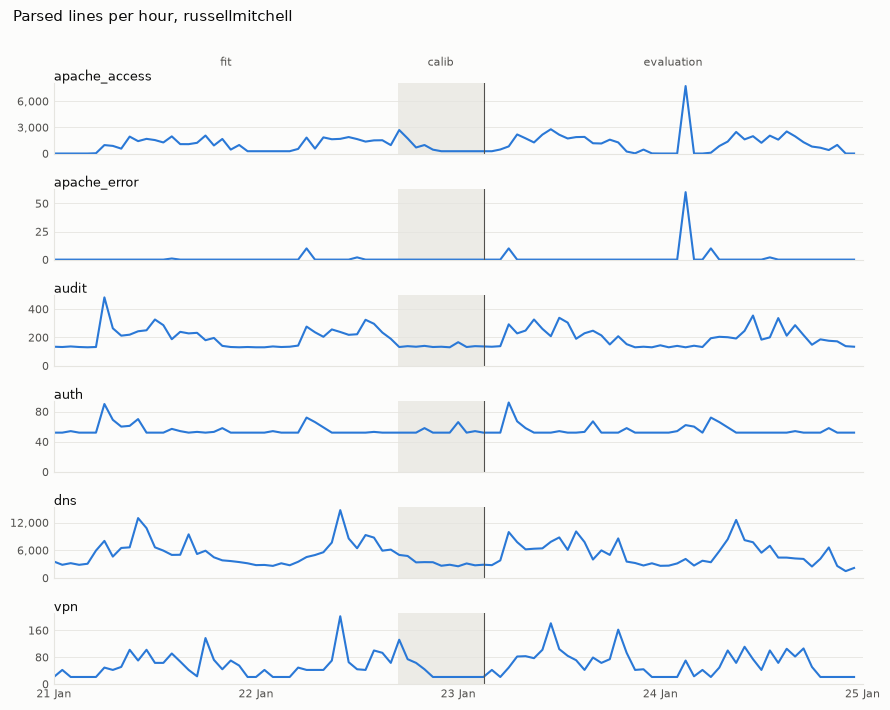

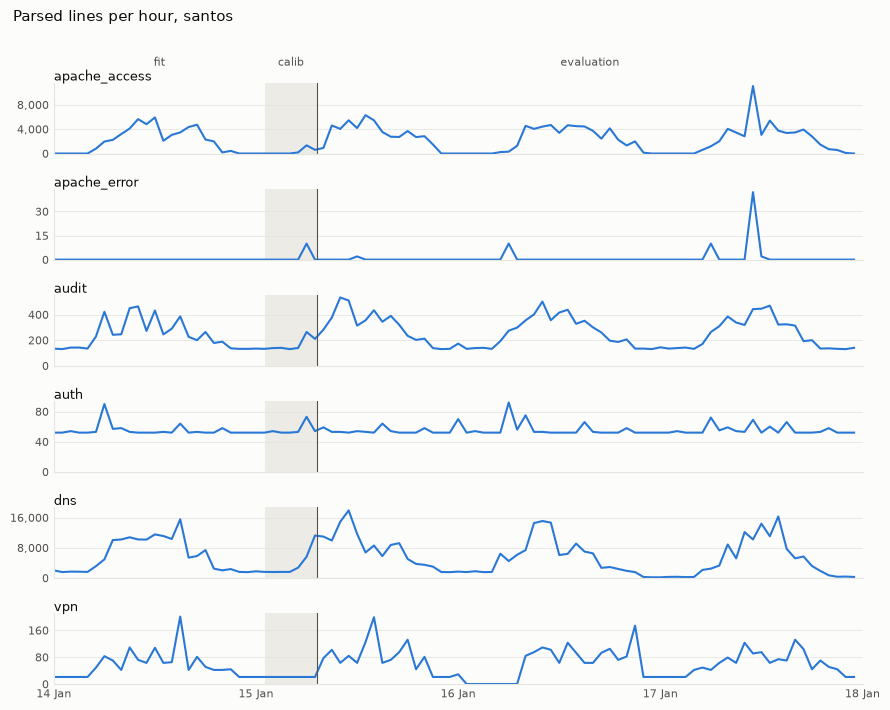

In [5]:
for testbed in TESTBEDS:
    show_figure(
        viz.plot_hourly_lines(
            eda.hourly_lines(connections[testbed]),
            periods[testbed],
            f"Parsed lines per hour, {testbed}",
            FIGURES / f"eda_hourly_lines_{testbed}.png",
        )
    )

## 3. Attack share and class imbalance

Parsed lines, so this is line-level imbalance; window-level numbers come in M4. Exfiltration dominates the labels, so `all without exfil` is the better picture of the rest of the attack.

In [6]:
for testbed in TESTBEDS:
    show(f"{testbed}: attack share", eda.attack_share(connections[testbed], periods[testbed]))

**russellmitchell: attack share**

,scope,log_type,lines,attack_lines,attack_share,normal_per_attack
0,simulation,apache_access,103337,7695,0.0745,12.4291
1,simulation,apache_error,95,36,0.3789,1.6389
2,simulation,audit,18740,11,0.0006,"1,702.6364"
3,simulation,auth,5319,8,0.0015,663.8750
4,simulation,dns,503498,54035,0.1073,8.3180
5,simulation,vpn,5537,28,0.0051,196.7500
6,simulation,all,636526,61813,0.0971,9.2976
7,simulation,all without exfil,583520,8807,0.0151,65.2564
8,evaluation,apache_access,55187,7695,0.1394,6.1718
9,evaluation,apache_error,82,36,0.4390,1.2778


**santos: attack share**

,scope,log_type,lines,attack_lines,attack_share,normal_per_attack
0,simulation,apache_access,210121,7794,0.0371,25.9593
1,simulation,apache_error,76,42,0.5526,0.8095
2,simulation,audit,24042,21,0.0009,"1,143.8571"
3,simulation,auth,5314,12,0.0023,441.8333
4,simulation,dns,531462,39426,0.0742,12.4800
5,simulation,vpn,5622,28,0.0050,199.7857
6,simulation,all,776637,47323,0.0609,15.4114
7,simulation,all without exfil,738076,8762,0.0119,83.2360
8,evaluation,apache_access,157319,7794,0.0495,19.1846
9,evaluation,apache_error,66,42,0.6364,0.5714


## 4. Phase timeline against log types with traces

The left panel shows each phase in the simulation. The dot marks phases too short to see as a bar. `dnsteal_exfil` starts before the simulation and is cut at its start. `reverse_shell` has no labeled lines on either testbed.

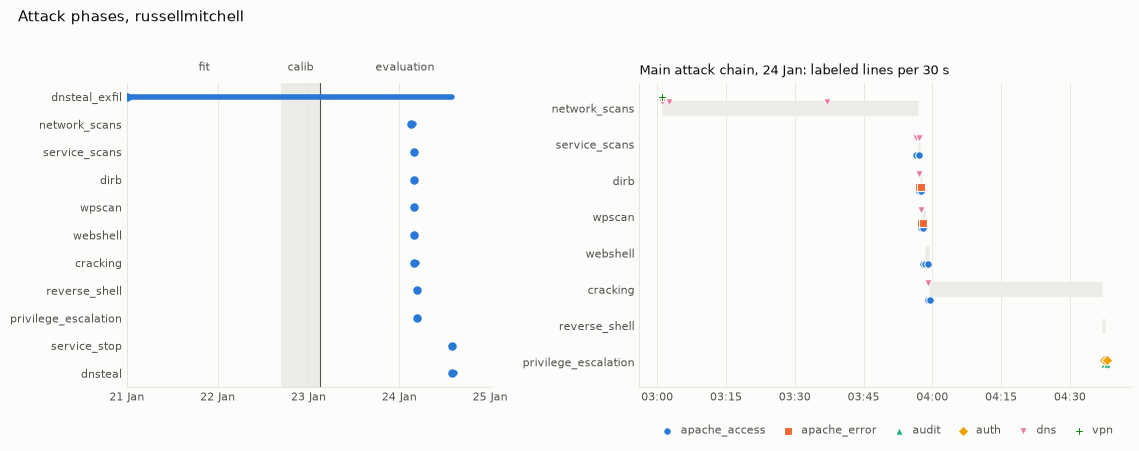

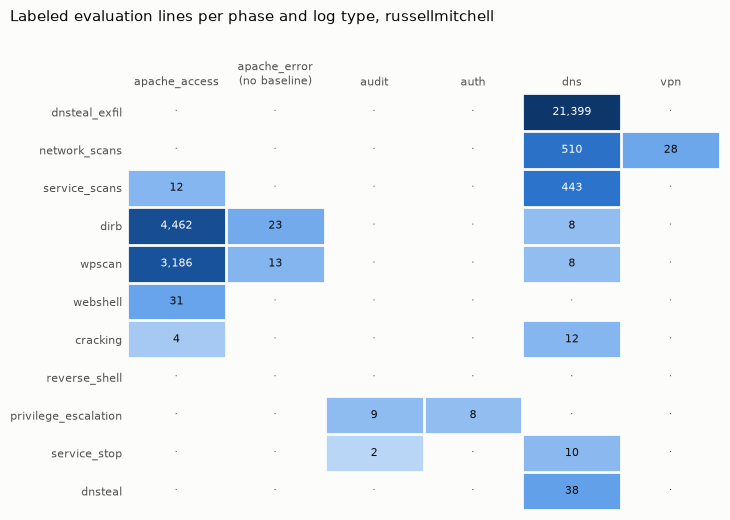

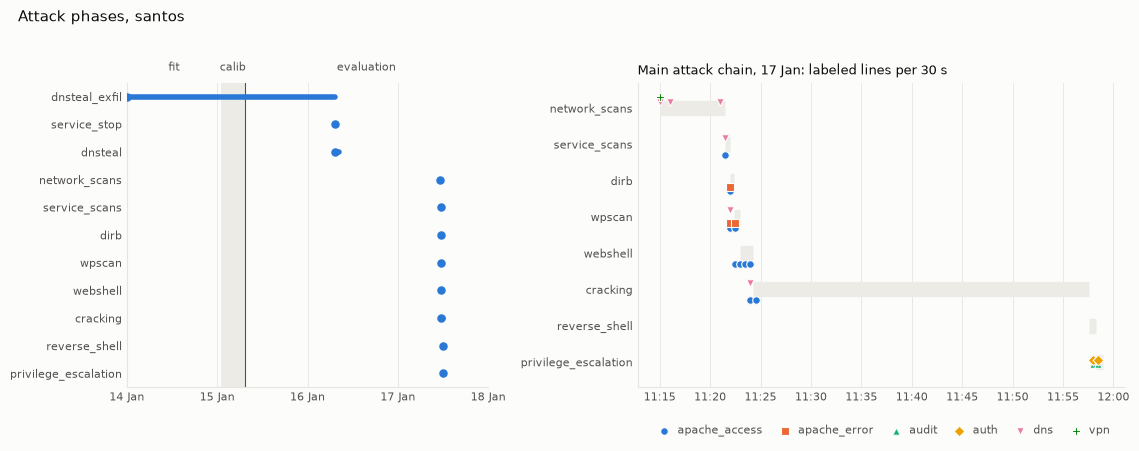

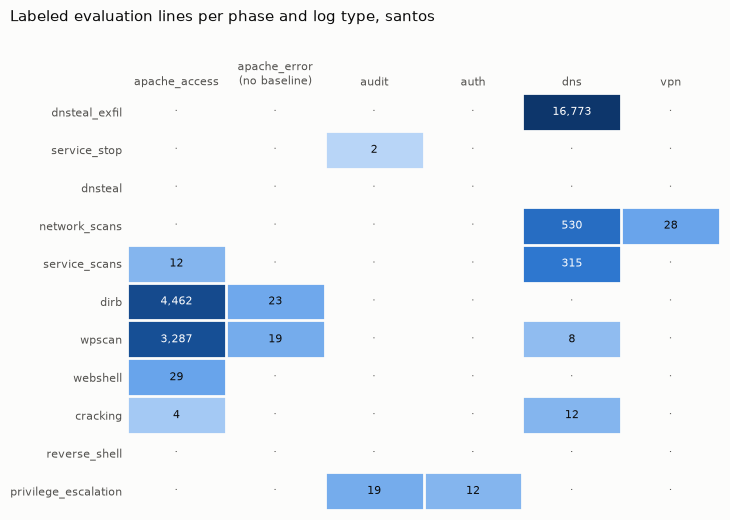

In [7]:
intervals = {t: eda.phase_intervals(connections[t]) for t in TESTBEDS}
traces = {t: eda.phase_traces(connections[t], periods[t]) for t in TESTBEDS}
for testbed in TESTBEDS:
    show_figure(
        viz.plot_phase_timeline(
            intervals[testbed],
            eda.labeled_timeline(connections[testbed]),
            periods[testbed],
            f"Attack phases, {testbed}",
            FIGURES / f"eda_phase_timeline_{testbed}.png",
        )
    )
    show_figure(
        viz.plot_phase_log_types(
            traces[testbed],
            list(intervals[testbed]["phase"]),
            [name for name in capability[testbed].index if name not in capable[testbed]],
            f"Labeled evaluation lines per phase and log type, {testbed}",
            FIGURES / f"eda_phase_log_types_{testbed}.png",
        )
    )

## 5. Phases with traces (§10.1, D19)

A phase counts if the evaluation period holds at least one of its labeled lines, in a baseline-capable log type for the primary denominator. `required` is the fewest detected phases that reach the 80% target.

In [8]:
denominators = {t: eda.phase_denominators(connections[t], traces[t], capable[t]) for t in TESTBEDS}
for testbed in TESTBEDS:
    table = denominators[testbed]
    show(f"{testbed}: phases", table)
    show(f"{testbed}: denominators", eda.denominator_summary(table))
    only_no_baseline = table[table["all_parsed"] & ~table["primary"]]["phase"].tolist()
    print("Phases with traces only in log types without a baseline:", only_no_baseline or "none")
    print("Phases left out for lack of traces:", table[~table["all_parsed"]]["phase"].tolist())

**russellmitchell: phases**

,phase,labeled,labeled_eval,log_types,baseline_log_types,primary,all_parsed
0,dnsteal_exfil,53006,21399,dns,dns,True,True
1,network_scans,538,538,"dns, vpn","dns, vpn",True,True
2,service_scans,455,455,"apache_access, dns","apache_access, dns",True,True
3,dirb,4493,4493,"apache_access, apache_error, dns","apache_access, dns",True,True
4,wpscan,3207,3207,"apache_access, apache_error, dns","apache_access, dns",True,True
5,webshell,31,31,apache_access,apache_access,True,True
6,cracking,16,16,"apache_access, dns","apache_access, dns",True,True
7,reverse_shell,0,0,,,False,False
8,privilege_escalation,17,17,"audit, auth","audit, auth",True,True
9,service_stop,12,12,"audit, dns","audit, dns",True,True


**russellmitchell: denominators**

,variant,phases,required
0,primary (baseline-capable log types),10,8
1,secondary (all parsed log types),10,8
2,secondary (primary without dnsteal_exfil),9,8


Phases with traces only in log types without a baseline: none
Phases left out for lack of traces: ['reverse_shell']


**santos: phases**

,phase,labeled,labeled_eval,log_types,baseline_log_types,primary,all_parsed
0,dnsteal_exfil,38561,16773,dns,dns,True,True
1,service_stop,2,2,audit,audit,True,True
2,dnsteal,0,0,,,False,False
3,network_scans,558,558,"dns, vpn","dns, vpn",True,True
4,service_scans,327,327,"apache_access, dns","apache_access, dns",True,True
5,dirb,4485,4485,"apache_access, apache_error",apache_access,True,True
6,wpscan,3314,3314,"apache_access, apache_error, dns","apache_access, dns",True,True
7,webshell,29,29,apache_access,apache_access,True,True
8,cracking,16,16,"apache_access, dns","apache_access, dns",True,True
9,reverse_shell,0,0,,,False,False


**santos: denominators**

,variant,phases,required
0,primary (baseline-capable log types),9,8
1,secondary (all parsed log types),9,8
2,secondary (primary without dnsteal_exfil),8,7


Phases with traces only in log types without a baseline: none
Phases left out for lack of traces: ['dnsteal', 'reverse_shell']


## 6. Label gaps

Labels cover 8 files per testbed, so attack activity elsewhere is unlabeled. These are estimates.

### 6.1 Exfiltration on `inet-dns`

Attacker domains come from lines labeled `dnsteal`. On `inet-firewall` the domain match can be checked against the labels, and it agrees exactly: no unlabeled match and no labeled line outside. So the same match can be trusted on `inet-dns`, which has no labels. This gap is why D17 marks that stream label-ambiguous.

In [9]:
addresses = {t: eda.attacker_ips(connections[t]) for t in TESTBEDS}
domains = {t: eda.exfil_domains(connections[t]) for t in TESTBEDS}
for testbed in TESTBEDS:
    print(testbed, "attacker addresses:", addresses[testbed], "exfil domains:", domains[testbed])
    gap = eda.exfil_gap(connections[testbed], domains[testbed])
    show(f"{testbed}: exfiltration by domain match", gap)

russellmitchell attacker addresses: {'172.19.131.174': 'tunnel', '192.168.230.122': 'external'} exfil domains: ['kennedy-mendoza.info']


**russellmitchell: exfiltration by domain match**

,host,dns_lines,exfil_lines,exfil_queries,labeled,unlabeled,labeled_exfil_outside,exfil_share
0,inet-dns,227598,53052,17692,0,53052,0,0.2331
1,inet-firewall,275900,53054,17693,53054,0,0,0.1923


santos attacker addresses: {'172.21.128.119': 'tunnel', '10.229.2.216': 'external'} exfil domains: ['kiirjekuimkpcrcioastvkeodpnimx.biz']


**santos: exfiltration by domain match**

,host,dns_lines,exfil_lines,exfil_queries,labeled,unlabeled,labeled_exfil_outside,exfil_share
0,inet-dns,255795,38559,12853,0,38559,0,0.1507
1,inet-firewall,275667,38561,12854,38561,0,0,0.1399


### 6.2 Attacker addresses inside phase windows

Lines naming an attacker address inside a published phase ±60 s, without the exfiltration lines above. `external` is the attacker's own host, so its unlabeled lines are the **low estimate**. `all roles` is an **upper bound**: the tunnel address comes from the VPN pool and also serves ordinary users, as the large counts outside the windows show. The `dnsteal` window, an hour with no attacker traffic in `attacks.log`, is a clear case of that.

In [10]:
ip_lines = {t: eda.attacker_ip_lines(connections[t], addresses[t], domains[t]) for t in TESTBEDS}
for testbed in TESTBEDS:
    show(f"{testbed}: estimate", eda.attacker_gap_summary(ip_lines[testbed]))
    show(f"{testbed}: by phase", eda.attacker_gap_by(ip_lines[testbed], ["phase", "role"]))
    show(
        f"{testbed}: by log type and host",
        eda.attacker_gap_by(ip_lines[testbed], ["log_type", "host"]),
    )

**russellmitchell: estimate**

,role,lines_in_windows,labeled,unlabeled,gap_share,unlabeled_outside_windows
0,external,78,28,50,0.6410,72
1,tunnel,8442,7979,463,0.0548,39147
2,all roles,8520,8007,513,0.0602,39219


**russellmitchell: by phase**

,phase,role,lines,labeled,unlabeled
0,cracking,external,21,0,21
1,cracking,tunnel,3,3,0
2,dirb,tunnel,4487,4487,0
3,dnsteal,tunnel,413,0,413
4,network_scans,external,28,28,0
5,network_scans,tunnel,164,164,0
6,reverse_shell,tunnel,4,0,4
7,service_scans,external,29,0,29
8,service_scans,tunnel,133,92,41
9,service_stop,tunnel,3,0,3


**russellmitchell: by log type and host**

,log_type,host,lines,labeled,unlabeled
0,apache_access,cloud_share,12,0,12
1,apache_access,intranet_server,7696,7695,1
2,apache_access,webserver,371,0,371
3,apache_error,intranet_server,36,36,0
4,apache_error,webserver,24,0,24
5,auth,cloud_share,1,0,1
6,auth,davey_mail,1,0,1
7,auth,inet-dns,1,0,1
8,auth,inet-firewall,1,0,1
9,auth,internal_share,1,0,1


... (2 outputs left out)

**santos: by phase**

,phase,role,lines,labeled,unlabeled
0,cracking,tunnel,321,4,317
1,dirb,tunnel,4485,4485,0
2,dnsteal,tunnel,173,0,173
3,network_scans,external,28,28,0
4,network_scans,tunnel,271,170,101
5,privilege_escalation,tunnel,2,0,2
6,reverse_shell,tunnel,4,0,4
7,service_scans,external,2,0,2
8,service_scans,tunnel,91,69,22
9,webshell,tunnel,33,29,4


**santos: by log type and host**

,log_type,host,lines,labeled,unlabeled
0,apache_access,cloud_share,12,0,12
1,apache_access,intranet_server,7926,7794,132
2,apache_access,webserver,336,0,336
3,apache_error,intranet_server,42,42,0
4,auth,cloud_share,1,0,1
5,auth,inet-dns,1,0,1
6,auth,internal_share,1,0,1
7,auth,intranet_server,1,0,1
8,auth,mail,1,0,1
9,dns,inet-dns,1,0,1


### 6.3 Stderr lines in Apache error logs

`parse_ok=False` text. On `intranet_server` it is attacker output: `wget` progress and password cracking. It starts at the second of the `crack_wphash` step in `attacks.log`, 33 minutes or more before the reverse shell, so it came through the webshell. It carries no label, and its `ts` is inherited from an earlier record, hours off the time written inside it. D14 keeps these lines out of windows, so they cannot be detected or counted as false positives. The rest is Samba noise on `cloud_share`.

In [11]:
for testbed in TESTBEDS:
    show(f"{testbed}: stderr text", eda.stderr_gap(connections[testbed]))

**russellmitchell: stderr text**

,host,file,kind,lines,labeled,inherited_ts,first_written,last_written
0,cloud_share,logs/apache2/error.log.2,noise,238,0,2022-01-23 06:25:02,NaN,NaN
1,cloud_share,logs/apache2/error.log.3,noise,672,0,2022-01-22 06:25:03,NaN,NaN
2,intranet_server,logs/apache2/error.log.2,attacker output,3847,0,2022-01-23 06:25:03,2022-01-24 03:59:22,2022-01-24 03:59:46


**santos: stderr text**

,host,file,kind,lines,labeled,inherited_ts,first_written,last_written
0,cloud_share,logs/apache2/error.log,noise,266,0,2022-01-17 06:25:09,NaN,NaN
1,cloud_share,logs/apache2/error.log.1,noise,330,0,2022-01-16 06:25:11,NaN,NaN
2,cloud_share,logs/apache2/error.log.2,noise,274,0,2022-01-15 06:25:13,NaN,NaN
3,intranet_server,logs/apache2/error.log,attacker output,3847,0,2022-01-17 06:25:07,2022-01-17 11:24:16,2022-01-17 11:24:41


## 7. DNS contamination of the training period (D16)

Share of DNS lines that are exfiltration, per hour of the training period. `labeled_host_*` is `inet-firewall` from labels; `all_hosts_share` adds `inet-dns` by domain match. The training period stays as computed, so models will likely learn this traffic as normal. DNS results are reported separately in M5 and M11, and recall also without `dnsteal_exfil`.

**russellmitchell: contamination**

,period,hours,hours_with_exfil,labeled_host_share,hourly_min,hourly_median,hourly_max,all_hosts_share
0,fit,41,41,0.2012,0.0848,0.2255,0.4313,0.2184
1,calib,11,11,0.3108,0.0714,0.3033,0.4549,0.3630
2,training,52,52,0.2161,0.0714,0.2365,0.4549,0.2369


**santos: contamination**

,period,hours,hours_with_exfil,labeled_host_share,hourly_min,hourly_median,hourly_max,all_hosts_share
0,fit,26,26,0.2386,0.0856,0.3430,0.9019,0.2446
1,calib,6,6,0.4783,0.1317,0.6913,0.8832,0.4477
2,training,32,32,0.2605,0.0856,0.4595,0.9019,0.2647


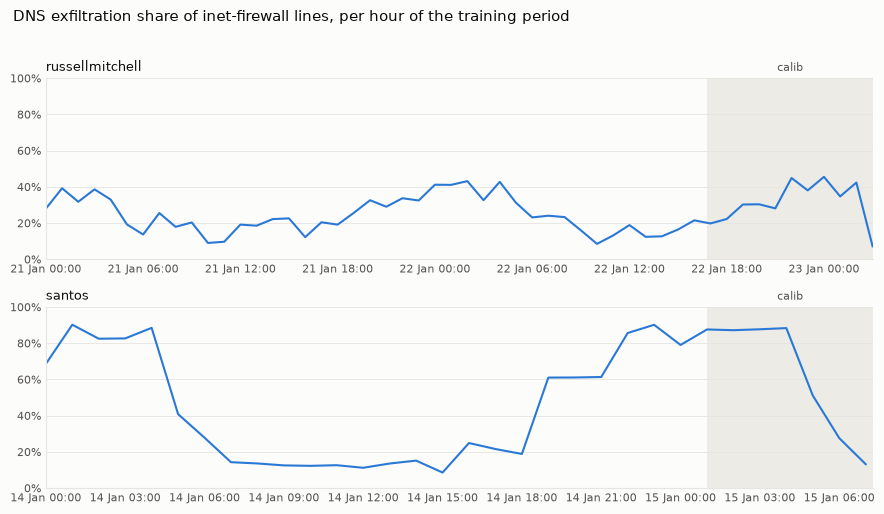

In [12]:
contamination = {t: eda.dns_contamination(connections[t], periods[t], domains[t]) for t in TESTBEDS}
for testbed in TESTBEDS:
    show(f"{testbed}: contamination", eda.contamination_summary(contamination[testbed]))
show_figure(
    viz.plot_dns_contamination(
        {t: (contamination[t], periods[t]) for t in TESTBEDS},
        FIGURES / "eda_dns_contamination.png",
    )
)

## 8. IDS alerts and the incidents/day budget (D20)

All AIT-ADS alerts in the evaluation period, divided by its length in days. Suricata alerts reach us through Wazuh. `fast.log` and `mail.info` repeat `eve.json` and `mail.log`, so `without mirrored files` is a lower bound. `largest_budget` is the most incidents/day that still gives 90% fewer than that scope; no detection result is used.

In [13]:
budget = settings.ml.incidents_per_day_budget
alerts = {t: baselines.load_ids_alerts(settings.paths.raw_dir / "ait_ads", t) for t in TESTBEDS}
rates = {t: baselines.alert_rates(alerts[t], periods[t]) for t in TESTBEDS}
for testbed in TESTBEDS:
    print(testbed, "evaluation days:", round(baselines.evaluation_days(periods[testbed]), 3))
    daily = baselines.daily_alerts(alerts[testbed], periods[testbed])
    show(f"{testbed}: alerts per UTC day", daily)
    show(f"{testbed}: budget of {budget} per day", baselines.budget_table(rates[testbed], budget))

russellmitchell evaluation days: 1.874


**russellmitchell: alerts per UTC day**

source,aminer,suricata,wazuh,total
day,,,,
2022-01-23,14,5430,4175,9619
2022-01-24,3643,4516,11657,19816


**russellmitchell: budget of 25 per day**

,scope,alerts,alerts_per_day,largest_budget,reduction_at_budget,feasible
0,all raw alerts,29435,"15,704.4831",1570,0.9984,True
1,without mirrored files,21888,"11,677.9252",1167,0.9979,True
2,aminer only,3657,"1,951.1226",195,0.9872,True
3,suricata only,9946,"5,306.4987",530,0.9953,True
4,wazuh only,15832,"8,446.8618",844,0.9970,True


santos evaluation days: 2.697


**santos: alerts per UTC day**

source,aminer,suricata,wazuh,total
day,,,,
2022-01-15,29,25208,7560,32797
2022-01-16,195,14958,7767,22920
2022-01-17,3548,8828,14905,27281


**santos: budget of 25 per day**

,scope,alerts,alerts_per_day,largest_budget,reduction_at_budget,feasible
0,all raw alerts,82998,"30,773.9030",3077,0.9992,True
1,without mirrored files,51214,"18,989.0680",1898,0.9987,True
2,aminer only,3772,"1,398.5778",139,0.9821,True
3,suricata only,48994,"18,165.9390",1816,0.9986,True
4,wazuh only,30232,"11,209.3862",1120,0.9978,True


## 9. Gold ATT&CK mapping

Every phase of the phases files needs an entry, and every ID must exist in ATT&CK without being revoked or deprecated.

In [14]:
gold = load_gold_mapping(settings.paths.gold_mapping_file)
missing = sorted({p for t in TESTBEDS for p in intervals[t]["phase"]} - set(gold))
print("Phases without a gold entry:", missing or "none")
if settings.paths.attack_stix_file.is_file():
    techniques, version = attack_techniques(settings.paths.attack_stix_file)
    print(f"ATT&CK {version}: unusable gold IDs:", unusable_gold_ids(gold, techniques) or "none")
else:
    print("ATT&CK data not available, IDs not checked")
display(pd.DataFrame({"phase": gold.keys(), "techniques": [", ".join(v) for v in gold.values()]}))

Phases without a gold entry: none


ATT&CK 20.1: unusable gold IDs: none


,phase,techniques
0,network_scans,"T1046, T1018"
1,service_scans,T1046
2,dirb,T1595.003
3,wpscan,"T1595.002, T1595.003"
4,webshell,"T1190, T1505.003"
5,cracking,T1110.002
6,reverse_shell,"T1059.004, T1059"
7,privilege_escalation,"T1078.003, T1548.003, T1078"
8,service_stop,T1489
9,dnsteal,"T1048.003, T1048, T1071.004"


## 10. Summary

The numbers that go into `reports/targets.md` and `status.md`.

In [15]:
rows = {}
for testbed in TESTBEDS:
    share = eda.attack_share(connections[testbed], periods[testbed])
    share = share.set_index(["scope", "log_type"])
    summary = eda.denominator_summary(denominators[testbed])
    gap = eda.attacker_gap_summary(ip_lines[testbed]).set_index("role")
    exfil = eda.exfil_gap(connections[testbed], domains[testbed]).set_index("host")
    dirty = eda.contamination_summary(contamination[testbed]).set_index("period")
    output = eda.stderr_gap(connections[testbed]).query("kind == 'attacker output'")
    rate = rates[testbed].set_index("scope")
    rows[testbed] = {
        "attack share, evaluation": f"{share.loc[('evaluation', 'all'), 'attack_share']:.2%}",
        "attack share, evaluation, without exfil": (
            f"{share.loc[('evaluation', 'all without exfil'), 'attack_share']:.2%}"
        ),
        "phases with traces, primary": int(summary["phases"].iloc[0]),
        "phases with traces, all parsed log types": int(summary["phases"].iloc[1]),
        "phases with traces, without dnsteal_exfil": int(summary["phases"].iloc[2]),
        "unlabeled exfiltration lines on inet-dns": int(exfil.loc["inet-dns", "unlabeled"]),
        "unlabeled attacker lines in windows, low": int(gap.loc["external", "unlabeled"]),
        "unlabeled attacker lines in windows, high": int(gap.loc["all roles", "unlabeled"]),
        "unlabeled stderr lines of the attacker": int(output["lines"].sum()),
        "exfiltration share of training DNS lines": (
            f"{dirty.loc['training', 'labeled_host_share']:.1%}"
        ),
        "raw IDS alerts per day": round(float(rate.loc["all raw alerts", "alerts_per_day"])),
        "incidents per day budget": budget,
        "incident limit for the evaluation period": int(
            budget * baselines.evaluation_days(periods[testbed])
        ),
    }
display(pd.DataFrame(rows))

,russellmitchell,santos
"attack share, evaluation",9.86%,4.65%
"attack share, evaluation, without exfil",3.09%,1.65%
"phases with traces, primary",10,9
"phases with traces, all parsed log types",10,9
"phases with traces, without dnsteal_exfil",9,8
unlabeled exfiltration lines on inet-dns,53052,38559
"unlabeled attacker lines in windows, low",50,2
"unlabeled attacker lines in windows, high",513,625
unlabeled stderr lines of the attacker,3847,3847
exfiltration share of training DNS lines,21.6%,26.0%


In [16]:
for connection in connections.values():
    connection.close()